<a href="https://colab.research.google.com/github/vikramsingh456/ai-ml/blob/dev/PCA_LAD_t_SNE_Supervised.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
!pip install kneed

Original Dataset:
   Income  Spending
0      20        20
1      22        25
2      25        22
3      60        60
4      62        65
5      65        62
6      90        90
7      92        88
8      95        92

 --------- K-Means Clustering---------
   Income  Spending  KMean_cluster
0      20        20              2
1      22        25              2
2      25        22              2
3      60        60              0
4      62        65              0
5      65        62              0
6      90        90              1
7      92        88              1
8      95        92              1

 Cluster Centers:
[[62.33333333 62.33333333]
 [92.33333333 90.        ]
 [22.33333333 22.33333333]]


/tmp/ipykernel_2072/2434201666.py:66: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


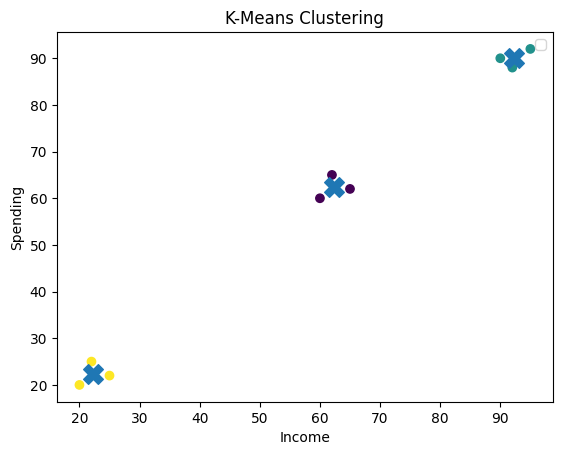


 ELBOW METHOD


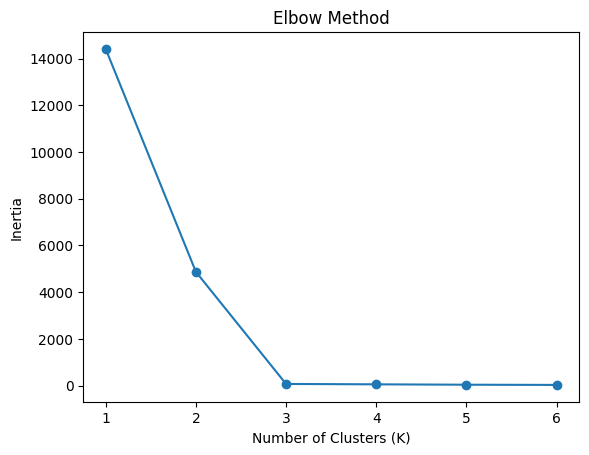


 Programmatic way to get K
The mathematically optimal K is: 3

 SILHOUETTE SCORE
Silhouette Score for K=2: 0.732
Silhouette Score for K=3: 0.894
Silhouette Score for K=4: 0.645
Silhouette Score for K=5: 0.45
Silhouette Score for K=6: 0.195

 --------- HIERARCHICAL CLUSTERING---------
   Income  Spending  KMean_cluster  Hierarchical_cluster
0      20        20              2                     1
1      22        25              2                     1
2      25        22              2                     1
3      60        60              0                     2
4      62        65              0                     2
5      65        62              0                     2
6      90        90              1                     0
7      92        88              1                     0
8      95        92              1                     0


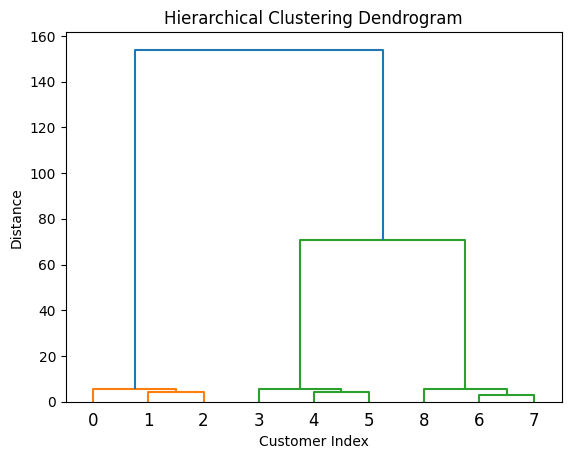


 --------- DBSCAN---------
   Income  Spending  KMean_cluster  Hierarchical_cluster  DBSCAN_Cluster
0      20        20              2                     1               0
1      22        25              2                     1               0
2      25        22              2                     1               0
3      60        60              0                     2               1
4      62        65              0                     2               1
5      65        62              0                     2               1
6      90        90              1                     0               2
7      92        88              1                     0               2
8      95        92              1                     0               2


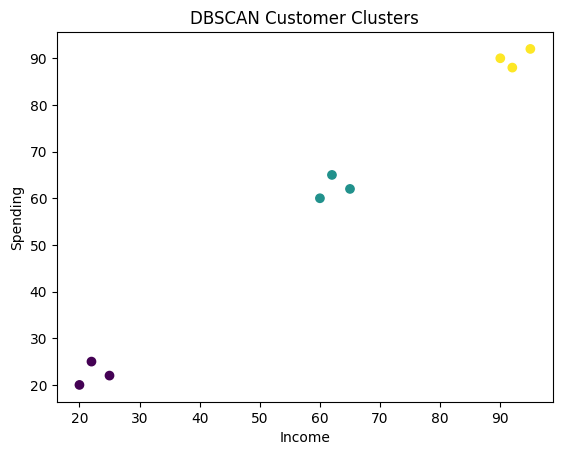


--- FINAL COMPARISON ---
   Income  Spending  KMean_cluster  Hierarchical_cluster  DBSCAN_Cluster
0      20        20              2                     1               0
1      22        25              2                     1               0
2      25        22              2                     1               0
3      60        60              0                     2               1
4      62        65              0                     2               1
5      65        62              0                     2               1
6      90        90              1                     0               2
7      92        88              1                     0               2
8      95        92              1                     0               2


In [7]:
# K- Means Implementaion

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import DBSCAN

from sklearn.metrics import silhouette_score

from scipy.cluster.hierarchy import dendrogram, linkage

from kneed import KneeLocator

data = {
    'Income': [
        20, 22, 25,
        60, 62, 65,
        90, 92, 95
    ],

    'Spending': [
        20, 25, 22,
        60, 65, 62,
        90, 88, 92
    ]
}

df = pd.DataFrame(data)

print("Original Dataset:")
print(df)

X = df[['Income', 'Spending']]

print("\n --------- K-Means Clustering---------")

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

df['KMean_cluster'] = kmeans.fit_predict(X)

print(df)

print("\n Cluster Centers:")

print(kmeans.cluster_centers_)

#Visulaize K-Mean cluster

plt.figure()
plt.scatter(df['Income'], df['Spending'], c=df['KMean_cluster'])

plt.scatter(kmeans.cluster_centers_[:, 0],
            kmeans.cluster_centers_[:, 1], marker='X', s=200)

plt.xlabel('Income')
plt.ylabel('Spending')

plt.title('K-Means Customer Clusters')



plt.title('K-Means Clustering')
plt.xlabel('Income')
plt.ylabel('Spending')
plt.legend()
plt.show()

#ELBOW METHOD

print("\n ELBOW METHOD")

inertia = []

for k in range(1, 7):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X)
    inertia.append(kmeans.inertia_)

plt.figure

plt.plot(
    range(1, 7),
    inertia,
    marker='o'
)

plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')

plt.title('Elbow Method')

plt.show()

print("\n Programmatic way to get K")

kl = KneeLocator(range(1,7), inertia, curve="convex", direction="decreasing")
optimal_k = kl.elbow

print(f"The mathematically optimal K is: {optimal_k}")

# SILHOUETTE  SCORE

print("\n SILHOUETTE SCORE")

for k in range (2, 7):
  model = KMeans(
      n_clusters=k,
      random_state=42,
      n_init=10
  )

  labels = model.fit_predict(X)

  score = silhouette_score(X, labels)

  print(f"Silhouette Score for K={k}: {round(score,3)}")

  #HIERARCHICAL CLUSTERING
print("\n --------- HIERARCHICAL CLUSTERING---------")

hierarchical = AgglomerativeClustering(
  n_clusters=3,
  linkage='ward'
)

df['Hierarchical_cluster'] = hierarchical.fit_predict(X)

print(df)

# Create Dendrogram

linked = linkage(X, 'ward')

plt.figure()

dendrogram(linked)

plt.xlabel('Customer Index')
plt.ylabel('Distance')

plt.title('Hierarchical Clustering Dendrogram')

plt.show()

#DBSCAN

print("\n --------- DBSCAN---------")

dbscan = DBSCAN(eps=8, min_samples=2)

df['DBSCAN_Cluster'] = dbscan.fit_predict(X)

print(df)

plt.figure()

plt.scatter(
  df['Income'],
  df['Spending'],
  c=df['DBSCAN_Cluster']
)


plt.xlabel('Income')
plt.ylabel('Spending')

plt.title('DBSCAN Customer Clusters')

plt.show()

print("\n--- FINAL COMPARISON ---")

print(
    df[
        [
            'Income',
            'Spending',
            'KMean_cluster',
            'Hierarchical_cluster',
            'DBSCAN_Cluster'
        ]
    ]
)


Original Data Shape
(150, 4)
PCA
(150, 2)

PCA Explained Variance Ratio
[0.72962445 0.22850762]

PCA Cumulative Explained Variance Ratio
[0.72962445 0.95813207]

 Total PCA Explained Variance Ratio
0.9581320720000166


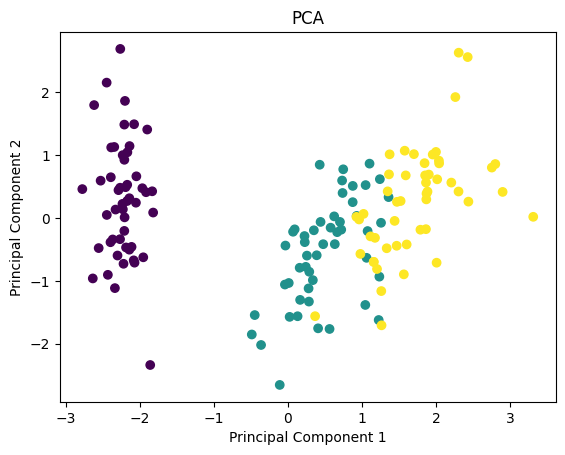


LDA
LDA Shape:
(150, 2)

LDA Explained Variance Ratio
[0.9912126 0.0087874]

LDA Cumulative Explained Variance Ratio
[0.9912126 1.       ]

 Total LDA Explained Variance Ratio
1.0


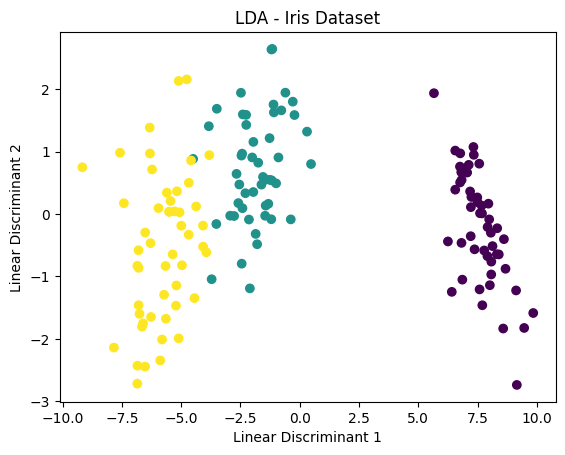


 t-SNE----------
t-SNE Shape:
(150, 2)


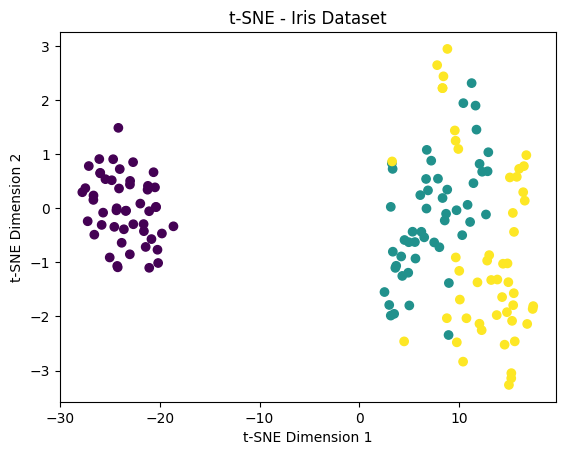


--- FINAL COMPARISON ---
Original Data Shape:
(150, 4)

PCA Shape:
(150, 2)

LDA Shape:
(150, 2)

t-SNE Shape:
(150, 2)
PCA   -> Preserve Variance
LDA   -> Separate Known Classes
t-SNE -> Visualize Similar Points


In [4]:
# ============================================================
# DIMENSIONALITY REDUCTION
# PCA + LDA + t-SNE
# Using the Iris Dataset
# ============================================================


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_iris

iris = load_iris();

X = iris.data
y = iris.target

print("Original Data Shape")
print(X.shape)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

#PCA

print("PCA")
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print(X_pca.shape)

print("\nPCA Explained Variance Ratio")
print(pca.explained_variance_ratio_)

print("\nPCA Cumulative Explained Variance Ratio")
print(np.cumsum(pca.explained_variance_ratio_))

print("\n Total PCA Explained Variance Ratio")
print(np.sum(pca.explained_variance_ratio_))


plt.figure()
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA')
plt.show()

#LDA

print("\nLDA")
lda = LinearDiscriminantAnalysis(n_components=2)
X_lda = lda.fit_transform(X_scaled, y)

print("LDA Shape:")
print(X_lda.shape)

print("\nLDA Explained Variance Ratio")
print(lda.explained_variance_ratio_)

print("\nLDA Cumulative Explained Variance Ratio")
print(np.cumsum(lda.explained_variance_ratio_))

print("\n Total LDA Explained Variance Ratio")
print(np.sum(lda.explained_variance_ratio_))

plt.figure()
plt.scatter(X_lda[:, 0], X_lda[:, 1], c=y)
plt.xlabel('Linear Discriminant 1')
plt.ylabel('Linear Discriminant 2')
plt.title('LDA - Iris Dataset')
plt.show()

#t-SNE

print("\n t-SNE----------")
tsne = TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(X_scaled)

print("t-SNE Shape:")
print(X_tsne.shape)

plt.figure()
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y)
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.title('t-SNE - Iris Dataset')
plt.show()

#FINAL SUMMARY

print("\n--- FINAL COMPARISON ---")
print("Original Data Shape:")
print(X.shape)
print("\nPCA Shape:")
print(X_pca.shape)
print("\nLDA Shape:")
print(X_lda.shape)
print("\nt-SNE Shape:")
print(X_tsne.shape)

print(
    "PCA   -> Preserve Variance"
)

print(
    "LDA   -> Separate Known Classes"
)

print(
    "t-SNE -> Visualize Similar Points"
)


Original Dataset:
    Math  Science  English  StudyHours  Performance
0     40       42       45           2            0
1     42       40       43           2            0
2     45       46       47           3            0
3     47       45       46           3            0
4     43       44       44           2            0
5     60       62       65           4            1
6     62       60       63           4            1
7     65       66       67           5            1
8     67       65       66           5            1
9     63       64       64           4            1
10    80       82       85           7            2
11    82       80       83           7            2
12    85       86       87           8            2
13    87       85       86           8            2
14    83       84       84           7            2

Original X Shape:
(15, 4)

PCA

PCA Result:
[[-2.61550009 -0.02427773]
 [-2.67671505  0.05605052]
 [-2.04547813  0.21549221]
 [-2.04574348  0.2502723

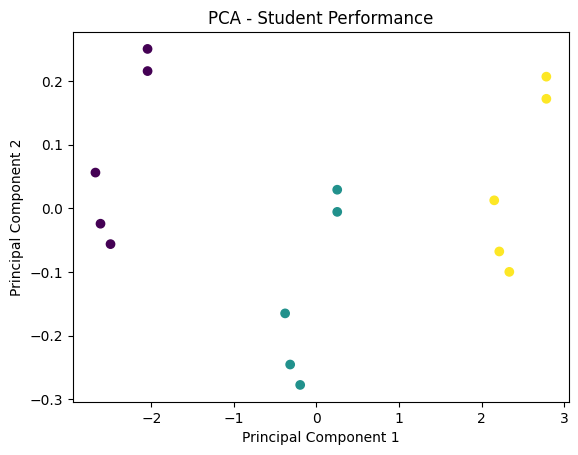


LDA

LDA Result:
[[ 9.09848543e+01 -4.80435823e-01]
 [ 9.27207064e+01  1.27497582e-01]
 [ 9.28920042e+01 -1.77248547e+00]
 [ 9.06644901e+01 -1.10841734e+00]
 [ 9.19086802e+01  7.71517595e-01]
 [-7.89814711e+00  1.13092292e+00]
 [-6.16229502e+00  1.73885632e+00]
 [-5.99099717e+00 -1.61126734e-01]
 [-8.21851128e+00  5.02941395e-01]
 [-6.97432120e+00  2.38287633e+00]
 [-8.56345855e+01 -6.14400484e-01]
 [-8.38987334e+01 -6.46707991e-03]
 [-8.37274355e+01 -1.90645013e+00]
 [-8.59549496e+01 -1.24238200e+00]
 [-8.47107595e+01  6.37552933e-01]]

LDA Shape:
(15, 2)


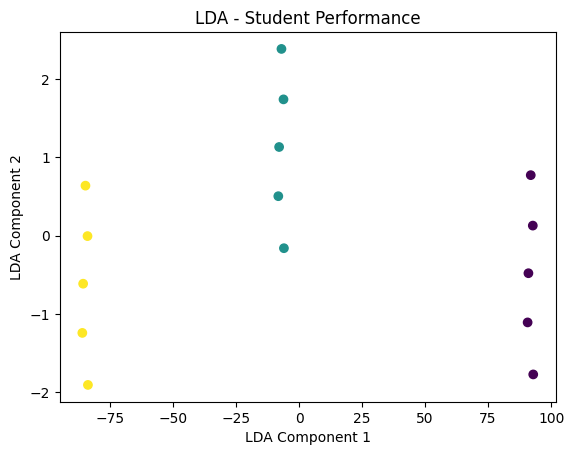


t-SNE

t-SNE Result:
[[ 13.639902   -21.49439   ]
 [ 12.467455   -21.502617  ]
 [ 12.543206   -19.63736   ]
 [ 11.790979   -20.311914  ]
 [ 13.584352   -20.31413   ]
 [  5.0775023  -11.353082  ]
 [  4.9541616  -12.584244  ]
 [  3.123788   -11.089401  ]
 [  4.0638175  -10.452722  ]
 [  3.7839875  -12.20823   ]
 [ -5.1514      -0.3718058 ]
 [ -4.3795633    0.44549543]
 [ -4.890385     1.55742   ]
 [ -6.0853944    1.2603625 ]
 [ -6.217073     0.05934984]]

t-SNE Shape:
(15, 2)


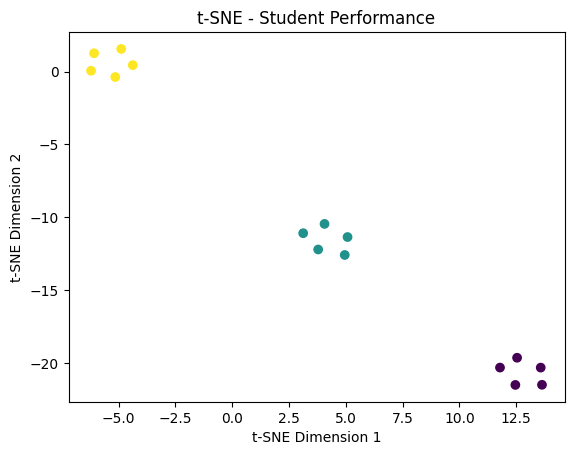


FINAL COMPARISON
Original Data Shape: (15, 4)
PCA Shape: (15, 2)
LDA Shape: (15, 2)
t-SNE Shape: (15, 2)

Remember:
PCA   -> Preserve Variance
LDA   -> Separate Known Classes
t-SNE -> Visualize Similar Observations


In [5]:
# ============================================================
# DIMENSIONALITY REDUCTION EXAMPLE
#
# PCA + LDA + t-SNE
#
# Example: Student Performance
# ============================================================


# ------------------------------------------------------------
# STEP 1: Import libraries
# ------------------------------------------------------------

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler

# PCA
from sklearn.decomposition import PCA

# LDA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# t-SNE
from sklearn.manifold import TSNE


# ------------------------------------------------------------
# STEP 2: Create simple student dataset
# ------------------------------------------------------------

data = {

    'Math': [
        40, 42, 45, 47, 43,
        60, 62, 65, 67, 63,
        80, 82, 85, 87, 83
    ],

    'Science': [
        42, 40, 46, 45, 44,
        62, 60, 66, 65, 64,
        82, 80, 86, 85, 84
    ],

    'English': [
        45, 43, 47, 46, 44,
        65, 63, 67, 66, 64,
        85, 83, 87, 86, 84
    ],

    'StudyHours': [
        2, 2, 3, 3, 2,
        4, 4, 5, 5, 4,
        7, 7, 8, 8, 7
    ],

    # Performance:
    # 0 = Low
    # 1 = Medium
    # 2 = High

    'Performance': [
        0, 0, 0, 0, 0,
        1, 1, 1, 1, 1,
        2, 2, 2, 2, 2
    ]
}


# Convert dictionary into DataFrame

df = pd.DataFrame(data)


print("Original Dataset:")
print(df)


# ------------------------------------------------------------
# STEP 3: Separate features X and target y
# ------------------------------------------------------------

X = df[
    [
        'Math',
        'Science',
        'English',
        'StudyHours'
    ]
]


# Known student performance category

y = df['Performance']


print("\nOriginal X Shape:")
print(X.shape)

# 15 students
# 4 features
#
# Output:
# (15, 4)


# ------------------------------------------------------------
# STEP 4: Standardize features
# ------------------------------------------------------------

# Marks and StudyHours have different scales.
#
# StandardScaler puts the features
# onto comparable scales.

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)


# ============================================================
# PART 1: PCA
# ============================================================

print("\n============================")
print("PCA")
print("============================")


# ------------------------------------------------------------
# STEP 5: Create PCA model
# ------------------------------------------------------------

# Reduce:
#
# 4 original features
#       ↓
# 2 principal components

pca = PCA(
    n_components=2
)


# ------------------------------------------------------------
# STEP 6: Apply PCA
# ------------------------------------------------------------

# IMPORTANT:
#
# PCA does NOT need y.
#
# PCA looks for directions that preserve
# as much variance as possible.

X_pca = pca.fit_transform(
    X_scaled
)


print("\nPCA Result:")
print(X_pca)


print("\nPCA Shape:")
print(X_pca.shape)


# ------------------------------------------------------------
# STEP 7: Explained variance
# ------------------------------------------------------------

print("\nExplained Variance Ratio:")

print(
    pca.explained_variance_ratio_
)


print("\nTotal Explained Variance:")

print(
    pca.explained_variance_ratio_.sum()
)


# ------------------------------------------------------------
# STEP 8: Plot PCA
# ------------------------------------------------------------

plt.figure()

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y
)

plt.xlabel(
    "Principal Component 1"
)

plt.ylabel(
    "Principal Component 2"
)

plt.title(
    "PCA - Student Performance"
)

plt.show()


# ============================================================
# PART 2: LDA
# ============================================================

print("\n============================")
print("LDA")
print("============================")


# ------------------------------------------------------------
# STEP 9: Create LDA model
# ------------------------------------------------------------

# We have 3 classes:
#
# 0 = Low
# 1 = Medium
# 2 = High
#
# Maximum LDA components:
#
# Number of classes - 1
#
# 3 - 1 = 2

lda = LinearDiscriminantAnalysis(
    n_components=2
)


# ------------------------------------------------------------
# STEP 10: Apply LDA
# ------------------------------------------------------------

# IMPORTANT:
#
# LDA DOES need y.
#
# It uses the known classes to find
# directions that separate the groups.

X_lda = lda.fit_transform(
    X_scaled,
    y
)


print("\nLDA Result:")
print(X_lda)


print("\nLDA Shape:")
print(X_lda.shape)


# ------------------------------------------------------------
# STEP 11: Plot LDA
# ------------------------------------------------------------

plt.figure()

plt.scatter(
    X_lda[:, 0],
    X_lda[:, 1],
    c=y
)

plt.xlabel(
    "LDA Component 1"
)

plt.ylabel(
    "LDA Component 2"
)

plt.title(
    "LDA - Student Performance"
)

plt.show()


# ============================================================
# PART 3: t-SNE
# ============================================================

print("\n============================")
print("t-SNE")
print("============================")


# ------------------------------------------------------------
# STEP 12: Create t-SNE model
# ------------------------------------------------------------

# t-SNE is mainly useful for visualization.
#
# We use perplexity=5 because our dataset
# contains only 15 students.

tsne = TSNE(
    n_components=2,
    perplexity=5,
    random_state=42,
    init='pca',
    learning_rate='auto'
)


# ------------------------------------------------------------
# STEP 13: Apply t-SNE
# ------------------------------------------------------------

# IMPORTANT:
#
# t-SNE does NOT need y.
#
# It tries to keep similar observations
# close together in the reduced space.

X_tsne = tsne.fit_transform(
    X_scaled
)


print("\nt-SNE Result:")
print(X_tsne)


print("\nt-SNE Shape:")
print(X_tsne.shape)


# ------------------------------------------------------------
# STEP 14: Plot t-SNE
# ------------------------------------------------------------

plt.figure()

plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=y
)

plt.xlabel(
    "t-SNE Dimension 1"
)

plt.ylabel(
    "t-SNE Dimension 2"
)

plt.title(
    "t-SNE - Student Performance"
)

plt.show()


# ============================================================
# FINAL COMPARISON
# ============================================================

print("\n============================")
print("FINAL COMPARISON")
print("============================")


print(
    "Original Data Shape:",
    X.shape
)

print(
    "PCA Shape:",
    X_pca.shape
)

print(
    "LDA Shape:",
    X_lda.shape
)

print(
    "t-SNE Shape:",
    X_tsne.shape
)


print("\nRemember:")

print(
    "PCA   -> Preserve Variance"
)

print(
    "LDA   -> Separate Known Classes"
)

print(
    "t-SNE -> Visualize Similar Observations"
)